# MSBA 501 Group Project: DoD contract dollars and local defense industries

**Decision-maker:** a State Economic Development Director
**Decision:** which defense industry (aerospace, scientific R&D or shipbuilding) to prioritize when recruiting and supporting firms in counties with DoD contracts
**Question:** Among U.S. counties that received DoD contract dollars, how is the number of aerospace, R&D and shipbuilding establishments associated with average annual DoD contract spending (2022–2024), holding population, metro status and region constant?
**Response:** `log_dod` = log of average annual DoD contract dollars, 2022–2024

Each section notes the slide it feeds. Put `county_data.csv` in the same folder as this notebook.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

%matplotlib inline
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "text.parse_math": False})   # so "$" prints as a dollar sign
BLUE, ORANGE = "#2a78d6", "#eb6834"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Load data and apply filters (slide 3: Data and filters)

In [2]:
raw = pd.read_csv("county_data.csv")
dod = "dod_avg_2022_2024"            # average annual DoD contract $, 2022-2024

step1 = raw[raw[dod].notna()]        # filter 1: drop counties with no DoD record
step2 = step1[step1[dod] > 0]        # filter 2: drop $0 and negative (log needs y > 0)

model_vars = ["log_dod", "log_aero_plants", "log_rnd_plants", "log_ship_plants",
              "log_pop_2020", "metro", "region"]
df = step2.dropna(subset=model_vars).copy()   # filter 3: drop rows missing any model variable

print(f"All U.S. counties:            {len(raw):,}")
print(f"No DoD contract record:       -{len(raw) - len(step1):,} -> {len(step1):,}")
print(f"DoD $0 ({(step1[dod] == 0).sum()}) or negative ({(step1[dod] < 0).sum()}): -{len(step1) - len(step2):,} -> {len(step2):,}")
print(f"Missing any model variable:   -{len(step2) - len(df):,} -> {len(df):,}")

All U.S. counties:            3,193
No DoD contract record:       -509 -> 2,684
DoD $0 (464) or negative (95): -559 -> 2,125
Missing any model variable:   -0 -> 2,125


## 2. Descriptive statistics (slide 4)
Industry variables are log(1 + count) because many counties have 0 establishments, and log(0) doesn't exist.

In [3]:
desc_vars = {dod: "DoD $/yr, 2022-24", "log_dod": "log DoD $ (response)",
             "aero_plants": "Aerospace establishments", "log_aero_plants": "log(1 + aerospace)",
             "rnd_plants": "R&D establishments", "log_rnd_plants": "log(1 + R&D)",
             "ship_plants": "Shipbuilding establishments", "log_ship_plants": "log(1 + shipbuilding)",
             "pop_2020": "Population, 2020", "log_pop_2020": "log population"}
desc = df[list(desc_vars)].agg(["mean", "std", "min", "median", "max", "skew"]).T
desc.index = desc_vars.values()
desc

,mean,std,min,median,max,skew
"DoD $/yr, 2022-24","185,635,423.416","1,016,652,485.003",2.167,"1,309,986.713","22,069,523,437.487",11.862
log DoD $ (response),14.174,3.697,0.773,14.086,23.817,0.016
Aerospace establishments,1.748,9.809,0.000,0.000,330.000,21.121
log(1 + aerospace),0.431,0.756,0.000,0.000,5.802,2.273
R&D establishments,18.935,80.409,0.000,2.000,"1,881.000",11.517
log(1 + R&D),1.389,1.458,0.000,1.099,7.540,1.188
Shipbuilding establishments,0.936,4.416,0.000,0.000,124.000,14.766
log(1 + shipbuilding),0.283,0.619,0.000,0.000,4.828,2.766
"Population, 2020","147,551.980","399,642.953",597.000,"43,086.000","9,996,634.000",11.240
log population,10.824,1.370,6.392,10.671,16.118,0.350


In [4]:
print(df["metro"].value_counts(), "\n")
print(df["region"].value_counts(), "\n")
for col in ["aero_plants", "rnd_plants", "ship_plants"]:
    print(f"Share with 0 {col}: {(df[col] == 0).mean():.0%}")

metro
Nonmetro    1107
Metro       1018
Name: count, dtype: int64 

region
South        965
Midwest      642
West         323
Northeast    195
Name: count, dtype: int64 

Share with 0 aero_plants: 67%
Share with 0 rnd_plants: 31%
Share with 0 ship_plants: 77%


## 3. EDA charts (slides 5–7)

**Chart 1, slide 5:** raw DoD $ is extremely right-skewed; the log is roughly symmetric, so we model log(DoD $).

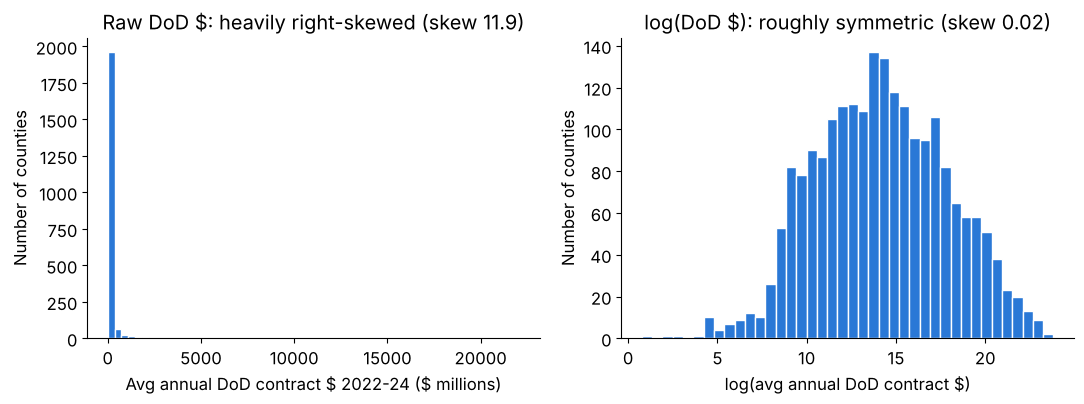

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hist(df[dod] / 1e6, bins=60, color=BLUE, edgecolor="white")
ax[0].set(title=f"Raw DoD $: heavily right-skewed (skew {df[dod].skew():.1f})",
          xlabel="Avg annual DoD contract $ 2022-24 ($ millions)", ylabel="Number of counties")
ax[1].hist(df["log_dod"], bins=40, color=BLUE, edgecolor="white")
ax[1].set(title=f"log(DoD $): roughly symmetric (skew {df['log_dod'].skew():.2f})",
          xlabel="log(avg annual DoD contract $)", ylabel="Number of counties")
fig.tight_layout(); plt.show()

**Chart 2, slide 6:** each industry rises roughly linearly with log(DoD $), so the predictors enter as log(1 + count).

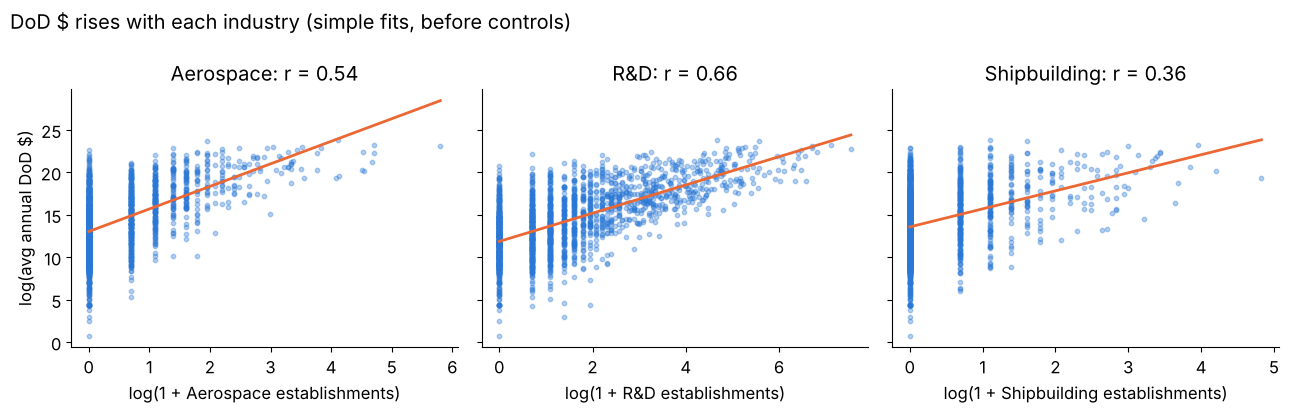

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for a, col, label in zip(ax, ["log_aero_plants", "log_rnd_plants", "log_ship_plants"],
                         ["Aerospace", "R&D", "Shipbuilding"]):
    a.scatter(df[col], df["log_dod"], s=10, alpha=0.35, color=BLUE)
    slope, intercept = np.polyfit(df[col], df["log_dod"], 1)       # simple fitted line
    xs = np.linspace(df[col].min(), df[col].max(), 50)
    a.plot(xs, intercept + slope * xs, color=ORANGE, lw=2)
    a.set(title=f"{label}: r = {df[col].corr(df['log_dod']):.2f}",
          xlabel=f"log(1 + {label} establishments)")
ax[0].set_ylabel("log(avg annual DoD $)")
fig.suptitle("DoD $ rises with each industry (simple fits, before controls)", x=0.01, ha="left")
fig.tight_layout(); plt.show()

**Chart 3, slide 7:** metro status and region shift DoD $, so both enter as dummies (baselines: Metro, Midwest).

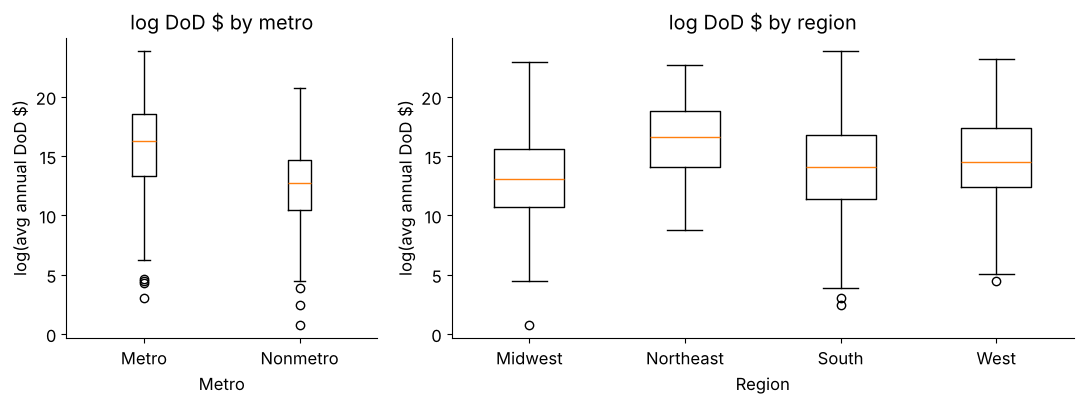

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 2]})
for a, col in zip(ax, ["metro", "region"]):
    levels = sorted(df[col].unique())
    a.boxplot([df.loc[df[col] == lv, "log_dod"] for lv in levels], tick_labels=levels)
    a.set(title=f"log DoD $ by {col}", xlabel=col.capitalize(), ylabel="log(avg annual DoD $)")
fig.tight_layout(); plt.show()

## 4. Multiple regression (slide 8)
OLS with 4 quantitative predictors plus dummies for metro status and region. Baselines: Metro, Midwest.

In [8]:
formula = ("log_dod ~ log_aero_plants + log_rnd_plants + log_ship_plants + log_pop_2020"
           " + C(metro, Treatment('Metro')) + C(region, Treatment('Midwest'))")
m = smf.ols(formula, data=df).fit()

ci = m.conf_int()
table = pd.DataFrame({"coef": m.params, "SE": m.bse, "t": m.tvalues, "p": m.pvalues,
                      "CI low": ci[0], "CI high": ci[1]})
table

,coef,SE,t,p,CI low,CI high
Intercept,4.328,0.850,5.092,0.000,2.662,5.995
"C(metro, Treatment('Metro'))[T.Nonmetro]",-0.413,0.146,-2.830,0.005,-0.700,-0.127
"C(region, Treatment('Midwest'))[T.Northeast]",1.124,0.224,5.017,0.000,0.685,1.564
"C(region, Treatment('Midwest'))[T.South]",0.341,0.136,2.504,0.012,0.074,0.608
"C(region, Treatment('Midwest'))[T.West]",0.428,0.186,2.294,0.022,0.062,0.793
log_aero_plants,0.663,0.108,6.133,0.000,0.451,0.875
log_rnd_plants,0.673,0.074,9.128,0.000,0.529,0.818
log_ship_plants,0.218,0.106,2.061,0.039,0.011,0.426
log_pop_2020,0.781,0.081,9.604,0.000,0.622,0.941


## 5. Interpreting the coefficients (slide 9)
Both sides are logged, so doubling (1 + establishments) multiplies DoD $ by 2^b: % change = (2^b − 1) × 100.
A dummy switches 0 → 1, which multiplies DoD $ by e^b: % change = (e^b − 1) × 100.

In [9]:
for v, label in [("log_aero_plants", "Aerospace"), ("log_rnd_plants", "R&D"),
                 ("log_ship_plants", "Shipbuilding"), ("log_pop_2020", "Population")]:
    b = m.params[v]
    print(f"{label:13s} b = {b:.3f}   doubling -> 2^{b:.3f} - 1 = {2**b - 1:+.0%}")

nonmetro = "C(metro, Treatment('Metro'))[T.Nonmetro]"
b = m.params[nonmetro]
print(f"Nonmetro      b = {b:.3f}   dummy    -> e^{b:.3f} - 1 = {np.exp(b) - 1:+.0%}")

Aerospace     b = 0.663   doubling -> 2^0.663 - 1 = +58%
R&D           b = 0.673   doubling -> 2^0.673 - 1 = +59%
Shipbuilding  b = 0.218   doubling -> 2^0.218 - 1 = +16%
Population    b = 0.781   doubling -> 2^0.781 - 1 = +72%
Nonmetro      b = -0.413   dummy    -> e^-0.413 - 1 = -34%


## 6. Model fit and diagnostics (slide 10)
R², adjusted R², se; VIF for multicollinearity (under 5 is fine); residuals vs fitted for the residual check
(we want an even band around 0).

In [10]:
se = np.sqrt(m.mse_resid)                     # residual standard error, in log units
print(f"R^2 = {m.rsquared:.3f}   adjusted R^2 = {m.rsquared_adj:.3f}   se = {se:.3f}   n = {int(m.nobs):,}")

X = m.model.exog
vif = pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])],
                index=m.model.exog_names[1:], name="VIF")
vif.round(2)

R^2 = 0.496   adjusted R^2 = 0.494   se = 2.630   n = 2,125


C(metro, Treatment('Metro'))[T.Nonmetro]       1.640
C(region, Treatment('Midwest'))[T.Northeast]   1.290
C(region, Treatment('Midwest'))[T.South]       1.410
C(region, Treatment('Midwest'))[T.West]        1.380
log_aero_plants                                2.050
log_rnd_plants                                 3.550
log_ship_plants                                1.320
log_pop_2020                                   3.810
Name: VIF, dtype: float64

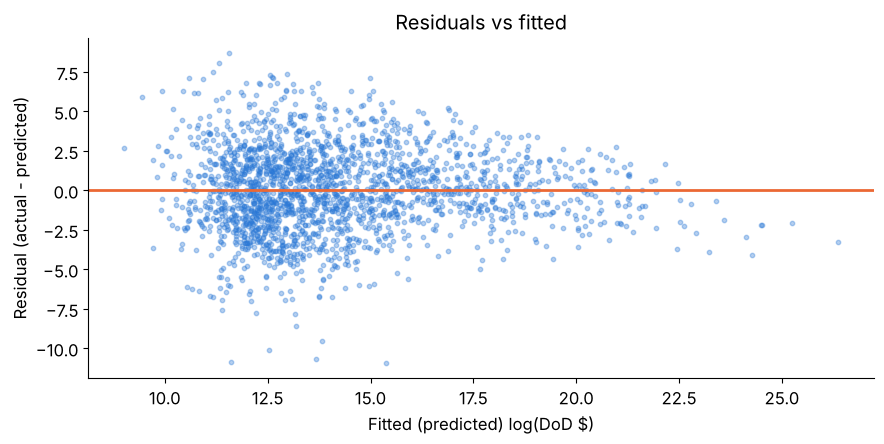

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(m.fittedvalues, m.resid, s=10, alpha=0.35, color=BLUE)
ax.axhline(0, color=ORANGE, lw=2)
ax.set(title="Residuals vs fitted", xlabel="Fitted (predicted) log(DoD $)",
       ylabel="Residual (actual - predicted)")
fig.tight_layout(); plt.show()

## 7. Prediction (slide 11)
Typical county = the sample median of each predictor (0 aerospace, 2 R&D, 0 shipbuilding, population 43,086),
Nonmetro and South (the most common category of each). We then add one establishment in each industry.
The **CI** is for the average of all counties with that profile; the **prediction interval** is for one county.

In [12]:
base = {"aero_plants": df["aero_plants"].median(), "rnd_plants": df["rnd_plants"].median(),
        "ship_plants": df["ship_plants"].median(), "pop_2020": df["pop_2020"].median()}
scenarios = {"Typical county": {}, "+1 aerospace": {"aero_plants": 1},
             "+1 R&D": {"rnd_plants": 1}, "+1 shipbuilding": {"ship_plants": 1}}

rows = []
for name, add in scenarios.items():
    v = {k: base[k] + add.get(k, 0) for k in base}
    x = pd.DataFrame({"log_aero_plants": [np.log(1 + v["aero_plants"])],
                      "log_rnd_plants": [np.log(1 + v["rnd_plants"])],
                      "log_ship_plants": [np.log(1 + v["ship_plants"])],
                      "log_pop_2020": [np.log(v["pop_2020"])],
                      "metro": ["Nonmetro"], "region": ["South"]})
    p = m.get_prediction(x).summary_frame(alpha=0.05)
    rows.append({"profile": name,
                 "predicted $M": np.exp(p["mean"].iloc[0]) / 1e6,
                 "CI low $M": np.exp(p["mean_ci_lower"].iloc[0]) / 1e6,
                 "CI high $M": np.exp(p["mean_ci_upper"].iloc[0]) / 1e6,
                 "PI low $": np.exp(p["obs_ci_lower"].iloc[0]),
                 "PI high $M": np.exp(p["obs_ci_upper"].iloc[0]) / 1e6,
                 "pred (log)": p["mean"].iloc[0],
                 "PI low (log)": p["obs_ci_lower"].iloc[0],
                 "PI high (log)": p["obs_ci_upper"].iloc[0]})
pd.DataFrame(rows)

,profile,predicted $M,CI low $M,CI high $M,PI low $,PI high $M,pred (log),PI low (log),PI high (log)
0,Typical county,0.616,0.483,0.785,"3,522.091",107.592,13.330,8.167,18.494
1,+1 aerospace,0.975,0.766,1.241,"5,577.667",170.354,13.790,8.627,18.953
2,+1 R&D,0.747,0.580,0.963,"4,272.727",130.649,13.524,8.360,18.688
3,+1 shipbuilding,0.716,0.556,0.922,"4,095.961",125.240,13.482,8.318,18.646


In [13]:
# The prediction interval worked out by hand for the typical county (log scale)
p = rows[0]
t_crit = stats.t.ppf(0.975, m.df_resid)
se_pred = (p["PI high (log)"] - p["pred (log)"]) / t_crit
print(f"{p['pred (log)']:.3f} +/- {t_crit:.3f} x {se_pred:.3f} = [{p['PI low (log)']:.3f}, {p['PI high (log)']:.3f}]")

# How often does a county's actual value land inside its own 95% prediction interval?
allp = m.get_prediction(df).summary_frame(alpha=0.05)
inside = (df["log_dod"].values >= allp["obs_ci_lower"].values) & (df["log_dod"].values <= allp["obs_ci_upper"].values)
print(f"Counties inside their own 95% prediction interval: {inside.mean():.1%}")

13.330 +/- 1.961 x 2.633 = [8.167, 18.494]
Counties inside their own 95% prediction interval: 95.0%


## 8. Recommendation: t-tests and competing models (slide 12, extra credit)
t-test for each industry: H0: b = 0 vs H1: b ≠ 0, α = 0.05.

In [14]:
for v, label in [("log_aero_plants", "Aerospace"), ("log_rnd_plants", "R&D"), ("log_ship_plants", "Shipbuilding")]:
    lo, hi = ci.loc[v]
    decision = "Reject H0" if m.pvalues[v] < 0.05 else "Fail to reject H0"
    print(f"{label:13s} b = {m.params[v]:.3f}  t = {m.tvalues[v]:.2f}  p = {m.pvalues[v]:.3f}  "
          f"95% CI {lo:.2f} to {hi:.2f}  {decision}")

Aerospace     b = 0.663  t = 6.13  p = 0.000  95% CI 0.45 to 0.88  Reject H0
R&D           b = 0.673  t = 9.13  p = 0.000  95% CI 0.53 to 0.82  Reject H0
Shipbuilding  b = 0.218  t = 2.06  p = 0.039  95% CI 0.01 to 0.43  Reject H0


Competing models on the same counties:
A = main model; B = industries only; C = main + federal jobs; D = main model with 2017–19 (pre-COVID) DoD $ as the response.

In [15]:
pre = df[df["dod_avg_2017_2019"] > 0].copy()
pre["log_dod_pre"] = np.log(pre["dod_avg_2017_2019"])

models = {
    "A: main model": smf.ols(formula, data=df).fit(),
    "B: industries only": smf.ols("log_dod ~ log_aero_plants + log_rnd_plants + log_ship_plants", data=df).fit(),
    "C: main + federal jobs": smf.ols(formula + " + log_federal_jobs", data=df).fit(),
    "D: main, 2017-19 DoD $": smf.ols(formula.replace("log_dod ~", "log_dod_pre ~"), data=pre).fit(),
}
pd.DataFrame([{"model": name, "n": int(r.nobs), "adj R^2": r.rsquared_adj, "se": np.sqrt(r.mse_resid),
               "b aero": r.params["log_aero_plants"], "b R&D": r.params["log_rnd_plants"],
               "b ship": r.params["log_ship_plants"]} for name, r in models.items()])

,model,n,adj R^2,se,b aero,b R&D,b ship
0,A: main model,2125,0.494,2.630,0.663,0.673,0.218
1,B: industries only,2125,0.454,2.733,0.863,1.298,0.384
2,C: main + federal jobs,2125,0.543,2.499,0.485,0.454,0.212
3,"D: main, 2017-19 DoD $",1971,0.475,2.337,0.653,0.499,0.252


## 9. Limits: shipbuilding and geography (slide 13)
Region dummies don't control for coastline, so we refit the main model only on counties with at least one
shipbuilding establishment.

In [16]:
ship = smf.ols(formula, data=df[df["ship_plants"] > 0]).fit()
print(f"n = {int(ship.nobs)}   shipbuilding b = {ship.params['log_ship_plants']:.3f} "
      f"(p = {ship.pvalues['log_ship_plants']:.3f})   aerospace b = {ship.params['log_aero_plants']:.3f}")

n = 496   shipbuilding b = 0.477 (p = 0.005)   aerospace b = 0.459
